# 02: skeletons on all TableTennis1 photos (MediaPipe and RTMPose)

Runs both pose models on every photo in `data/TableTennis1/` (17 photos, realme GT Neo 3, 3072x4096, 2026-11-18), draws both skeletons, and compares them: keypoint disagreement, joint angles, and CPU time per photo. How each toolbox is called and why is explained in `01_single_still_walkthrough.ipynb`.

These photos are free-form poses (forehand, backhand, ready, follow-through), not the M1 protocol set: no tape markers and no repeated shots. So this notebook measures **model agreement**, not accuracy and not the noise floor.

Settings: full resolution (notebook 01, section 7b: downscaling moves keypoints by 4-12 px and saves little time, since both models crop and resize internally). One person per photo: MediaPipe `num_poses=1`; for RTMPose the person with the highest mean score.

Outputs:
- `test-logs/keypoints_mediapipe_TableTennis1_2026-11-18.csv` (33 landmarks) and `test-logs/keypoints_rtmpose-m_TableTennis1_2026-11-18.csv` (17 COCO joints). Columns `image, joint, x_px, y_px, conf`, raw model output in full-resolution pixels. `conf` is MediaPipe `visibility` or the RTMPose SimCC score (not comparable).
- `test-logs/angles_TableTennis1_2026-11-18.csv`: image-plane joint angles per photo and model.
- `data/derived/TableTennis1/<photo>_skeleton.jpg`: each photo with both skeletons (regenerable).

In [1]:
import csv, time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pose_tracker.stills import (ROOT, COCO, MP33, MP_TO_COCO, load_image, MediaPipePose, make_rtmpose,
                                 rtmpose_main_person, joint_angles, torso_px, draw_skeleton)

IMGS = sorted((ROOT / "data/TableTennis1").glob("*.jpg"))
DATE = "2026-11-18"
LOG = ROOT / "test-logs"
OUT = ROOT / "data/derived/TableTennis1"
OUT.mkdir(parents=True, exist_ok=True)
print(len(IMGS), "photos")

17 photos


## 1. Run both models on every photo
Models are created once (load cost is paid once, notebook 01 section 8). Each photo is timed per step. The CPU clock drifts under sustained load on this laptop (notebook 01, section 8), so per-photo times are indicative; compare models within the same photo.

In [2]:
mpp, body = MediaPipePose(), make_rtmpose()
mpp(load_image(IMGS[0])[0]); body(load_image(IMGS[0])[0])  # warm-up, not timed

R = []
t_all = time.perf_counter()
for p in IMGS:
    t0 = time.perf_counter(); bgr, _ = load_image(p)
    t1 = time.perf_counter(); mp_xy, mp_vis = mpp(bgr)
    t2 = time.perf_counter(); rtm_xy, rtm_sc, n_det = rtmpose_main_person(body, bgr)
    t3 = time.perf_counter()
    R.append(dict(name=p.stem, mp_xy=mp_xy, mp_vis=mp_vis, rtm_xy=rtm_xy, rtm_sc=rtm_sc, n_det=n_det,
                  t_load=1000*(t1-t0), t_mp=1000*(t2-t1), t_rtm=1000*(t3-t2)))
t_all = time.perf_counter() - t_all
mpp.close()
print(f"{len(R)} photos in {t_all:.1f} s ({1000*t_all/len(R):.0f} ms per photo, load + both models)")

INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7a56080034a0, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7a560c003790, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.


load /home/sebas/HobbyProjects/pose-tracker/models/rtmlib/yolox_m_humanart.onnx with onnxruntime backend
load /home/sebas/HobbyProjects/pose-tracker/models/rtmlib/rtmpose_m_body7_256x192.onnx with onnxruntime backend


W0000 00:00:1795030148.095543   43682 inference_runner_litert.cc:1433] Input tensor memory is not aligned according to LiteRt's memory alignment requirements. Reallocating memory and copying data.
W0000 00:00:1795030148.158055   43683 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x7a56080034a0, name=CpuAccelerator
INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x7a560c003790, name=CpuAccelerator


17 photos in 14.2 s (838 ms per photo, load + both models)


## 2. Save raw keypoints

In [3]:
def write_kpts(path, rows):
    with open(path, "w", newline="") as f:
        w = csv.writer(f); w.writerow(["image", "joint", "x_px", "y_px", "conf"])
        w.writerows(rows)

write_kpts(LOG / f"keypoints_mediapipe_TableTennis1_{DATE}.csv",
           [(r["name"], MP33[j], f"{r['mp_xy'][j,0]:.1f}", f"{r['mp_xy'][j,1]:.1f}", f"{r['mp_vis'][j]:.3f}")
            for r in R for j in range(33)])
write_kpts(LOG / f"keypoints_rtmpose-m_TableTennis1_{DATE}.csv",
           [(r["name"], COCO[j], f"{r['rtm_xy'][j,0]:.1f}", f"{r['rtm_xy'][j,1]:.1f}", f"{r['rtm_sc'][j]:.3f}")
            for r in R for j in range(17)])
print("written to", LOG)

written to /home/sebas/HobbyProjects/pose-tracker/test-logs


## 3. All skeletons
Orange = MediaPipe full (its 17 COCO-equivalent landmarks), blue = RTMPose-m. Title: photo index, median disagreement as % of torso length.

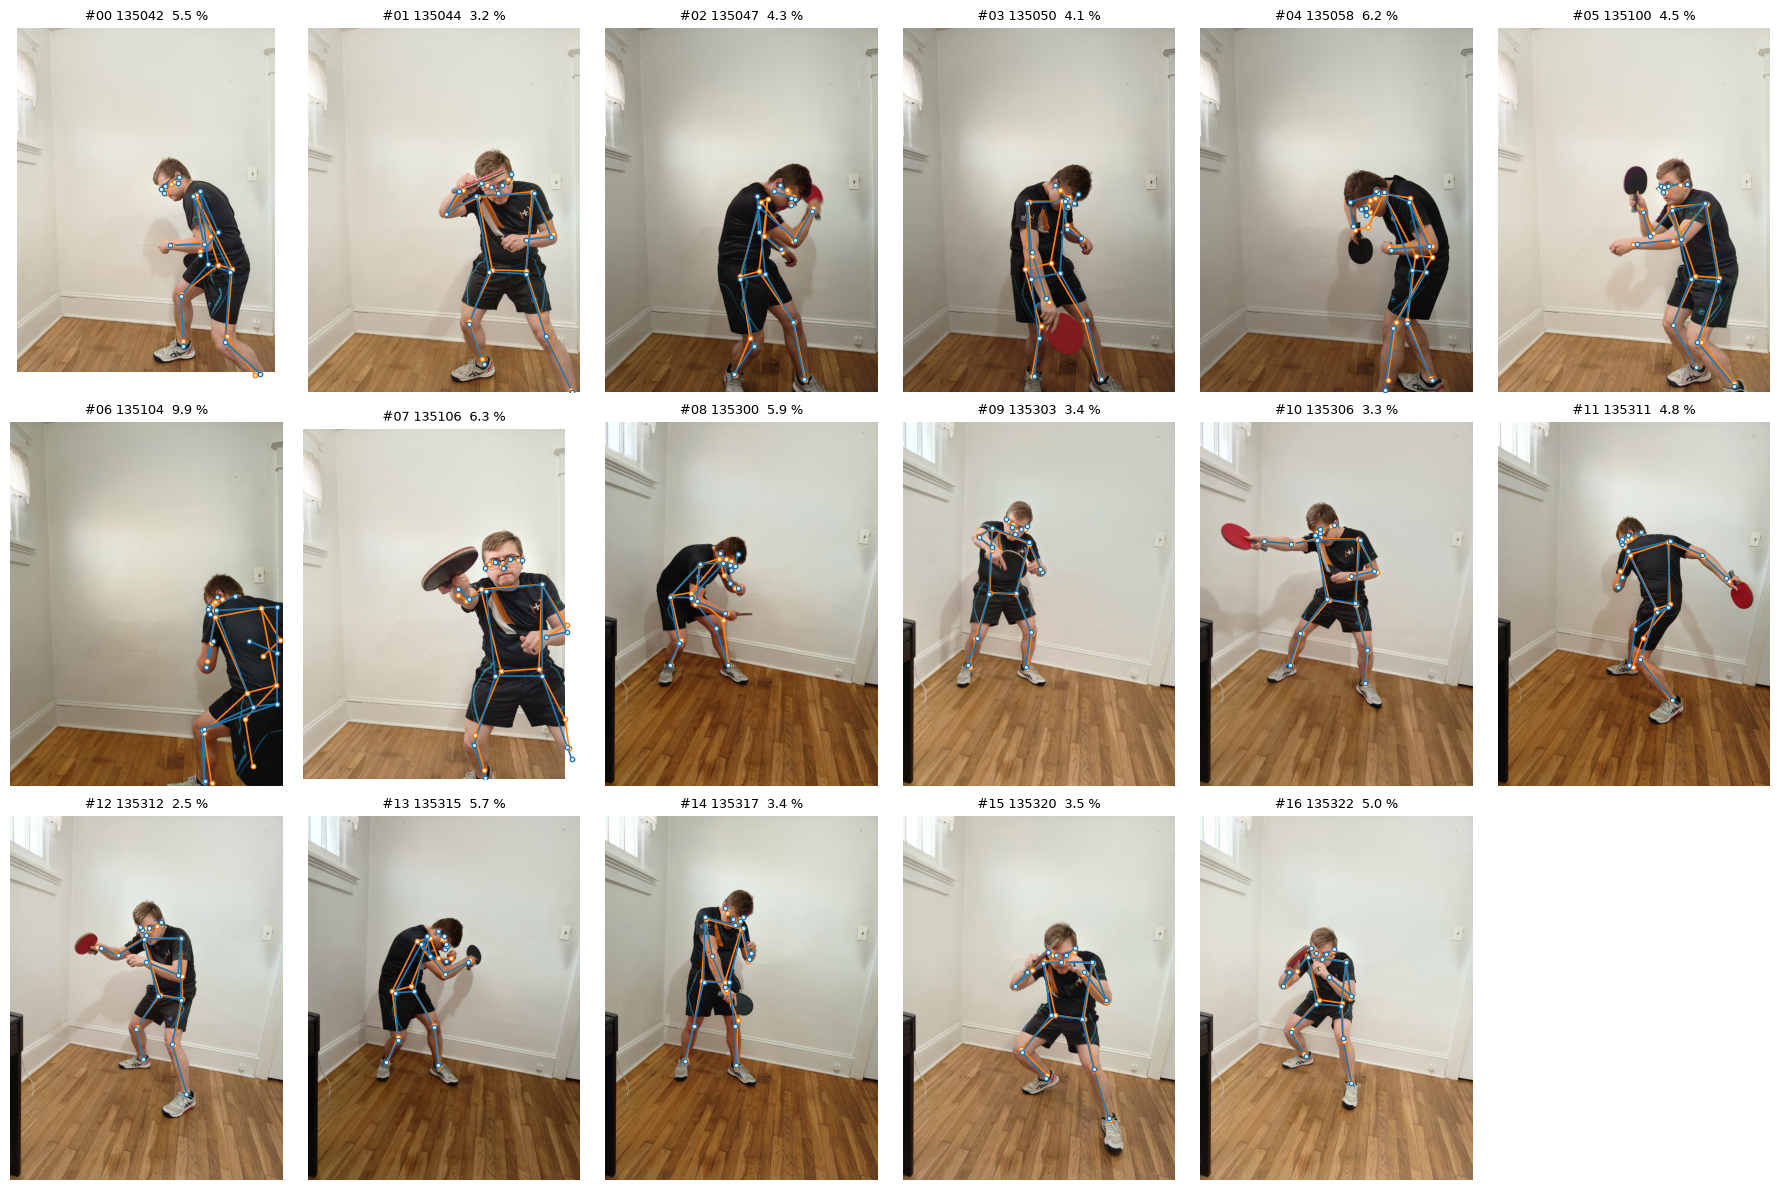

In [4]:
for r in R:
    r["mp17"] = r["mp_xy"][MP_TO_COCO]
    r["d"] = np.linalg.norm(r["mp17"] - r["rtm_xy"], axis=1)
    r["torso"] = torso_px(r["rtm_xy"])

ncol = 6
nrow = int(np.ceil(len(R) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(3 * ncol, 4 * nrow))
for ax in axs.flat:
    ax.axis("off")
for i, (r, ax) in enumerate(zip(R, axs.flat)):
    im, s = load_image(ROOT / "data/TableTennis1" / f"{r['name']}.jpg", 800)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    draw_skeleton(ax, r["mp17"] * s, "tab:orange", lw=1.2)
    draw_skeleton(ax, r["rtm_xy"] * s, "tab:blue", lw=1.2)
    ax.set_title(f"#{i:02d} {r['name'][-6:]}  {100*np.median(r['d'])/r['torso']:.1f} %", fontsize=9)
plt.tight_layout(); plt.show()

Save one annotated JPEG per photo (both skeletons, 1600 px long side) to `data/derived/TableTennis1/` for viewing at full size.

In [5]:
for r in R:
    im, s = load_image(ROOT / "data/TableTennis1" / f"{r['name']}.jpg", 1600)
    for xy, col in [(r["mp17"], (0, 140, 255)), (r["rtm_xy"], (200, 110, 30))]:  # BGR: orange, blue
        pts = np.round(xy * s).astype(int)
        for a, b in [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12),
                     (11, 13), (13, 15), (12, 14), (14, 16), (0, 1), (0, 2), (1, 3), (2, 4)]:
            cv2.line(im, tuple(pts[a]), tuple(pts[b]), col, 3, cv2.LINE_AA)
        for pt in pts:
            cv2.circle(im, tuple(pt), 5, col, -1, cv2.LINE_AA)
    cv2.imwrite(str(OUT / f"{r['name']}_skeleton.jpg"), im, [cv2.IMWRITE_JPEG_QUALITY, 90])
print(len(R), "files in", OUT)

17 files in /home/sebas/HobbyProjects/pose-tracker/data/derived/TableTennis1


## 4. Per-photo summary
- `n_det`: persons YOLOX found (above score 0.7). More than 1 would mean a second person or a false box.
- `mp_vis` / `rtm_sc`: mean confidence over the 17 joints, and the minimum (per model, not comparable across models).
- `med %` / `max %`: disagreement between the models, as % of torso length (mean shoulder-to-hip, RTMPose), and the joint with the largest gap.
- Times in ms: JPEG load, MediaPipe, RTMPose (YOLOX + pose head).

In [6]:
print(f"{'#':>2} {'photo':<18} {'n_det':>5} {'mp_vis':>11} {'rtm_sc':>11} {'torso':>5} {'med %':>6} {'max %':>6} {'max joint':<11} {'load':>5} {'MP':>4} {'RTM':>4}")
for i, r in enumerate(R):
    v, sc = r["mp_vis"][MP_TO_COCO], r["rtm_sc"]
    print(f"{i:2d} {r['name']:<18} {r['n_det']:5d} {v.mean():5.2f}/{v.min():5.2f} {sc.mean():5.2f}/{sc.min():5.2f} "
          f"{r['torso']:5.0f} {100*np.median(r['d'])/r['torso']:6.1f} {100*r['d'].max()/r['torso']:6.1f} "
          f"{COCO[r['d'].argmax()]:<11} {r['t_load']:5.0f} {r['t_mp']:4.0f} {r['t_rtm']:4.0f}")

 # photo              n_det      mp_vis      rtm_sc torso  med %  max % max joint    load   MP  RTM
 0 IMG20261118135042      1  0.85/ 0.06  0.74/ 0.30   942    5.5   13.0 r_hip         132   82  438
 1 IMG20261118135044      1  0.99/ 0.88  0.88/ 0.74   888    3.2    7.2 r_ear         135   93  524
 2 IMG20261118135047      1  0.91/ 0.33  0.78/ 0.41   862    4.3   18.1 l_ear         149   84  681
 3 IMG20261118135050      1  0.97/ 0.86  0.85/ 0.43   836    4.1   18.2 l_hip         145   92  764
 4 IMG20261118135058      1  0.87/ 0.39  0.78/ 0.43   876    6.2   39.8 r_elbow       173   85  572
 5 IMG20261118135100      1  0.98/ 0.87  0.87/ 0.63   848    4.5   11.0 l_elbow       171   98  827
 6 IMG20261118135104      1  0.72/ 0.02  0.58/ 0.22  1127    9.9   50.1 r_ankle       146  104  762
 7 IMG20261118135106      1  0.97/ 0.66  0.83/ 0.24  1039    6.3   31.9 l_knee        177   97  745
 8 IMG20261118135300      1  0.95/ 0.52  0.80/ 0.43   520    5.9   23.9 l_knee        150   86  673


## 5. Which joints do the models disagree on?
Distribution over the 17 photos of the per-joint distance between the two models, in % of torso length. Systematic offsets (different keypoint definitions, e.g. hips) show as a raised box with a small spread; occlusion or confusion shows as outliers.

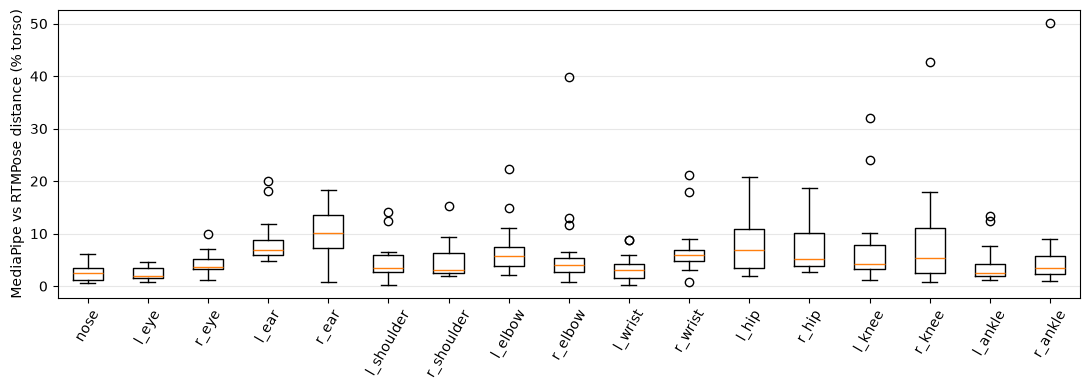

median over photos, % torso:
  nose 2.5, l_eye 2.0, r_eye 3.7, l_ear 6.9, r_ear 10.1, l_shoulder 3.5, r_shoulder 3.0, l_elbow 5.8, r_elbow 3.9, l_wrist 3.1, r_wrist 5.9, l_hip 7.0, r_hip 5.2, l_knee 4.3, r_knee 5.3, l_ankle 2.6, r_ankle 3.5


In [7]:
D = np.array([100 * r["d"] / r["torso"] for r in R])  # photos x joints
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(D, tick_labels=COCO)
ax.set_ylabel("MediaPipe vs RTMPose distance (% torso)")
ax.tick_params(axis="x", rotation=60); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()
print("median over photos, % torso:")
print("  " + ", ".join(f"{COCO[j]} {np.median(D[:, j]):.1f}" for j in range(17)))

## 6. Joint angles, both models
Image-plane angles (definitions in `pose_tracker.stills.joint_angles`; subject's left/right). An angle is marked `*` when one of its segments is shorter than 0.3 torso in the RTMPose skeleton (limb foreshortened, see notebook 01 section 6): those values are ill-conditioned and expected to disagree. The table of all angles is saved to `test-logs/`.

In [8]:
ANG = ["r_elbow", "l_elbow", "r_shoulder", "l_shoulder", "r_knee", "l_knee", "trunk_lean"]
SEG_OF = {"r_elbow": [(6, 8), (8, 10)], "l_elbow": [(5, 7), (7, 9)], "r_shoulder": [(12, 6), (6, 8)],
          "l_shoulder": [(11, 5), (5, 7)], "r_knee": [(12, 14), (14, 16)], "l_knee": [(11, 13), (13, 15)],
          "trunk_lean": []}

def short(r, k):
    return any(np.linalg.norm(r["rtm_xy"][i] - r["rtm_xy"][j]) < 0.3 * r["torso"] for i, j in SEG_OF[k])

rows, diffs = [], {k: [] for k in ANG}
print(f"{'#':>2} " + " ".join(f"{k:>17}" for k in ANG))
print(f"{'':>2} " + " ".join(f"{'MP / RTM':>17}" for _ in ANG))
for i, r in enumerate(R):
    a_mp, a_rtm = joint_angles(r["mp17"]), joint_angles(r["rtm_xy"])
    cells = []
    for k in ANG:
        flag = short(r, k)
        if not flag:
            diffs[k].append(abs(a_mp[k] - a_rtm[k]))
        cells.append(f"{a_mp[k]:6.1f} / {a_rtm[k]:6.1f}{'*' if flag else ' '}")
        rows.append((r["name"], k, f"{a_mp[k]:.1f}", f"{a_rtm[k]:.1f}", int(flag)))
    print(f"{i:2d} " + " ".join(f"{c:>17}" for c in cells))

with open(LOG / f"angles_TableTennis1_{DATE}.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["image", "angle", "mediapipe_deg", "rtmpose_deg", "short_segment"]); w.writerows(rows)

print("\n|MP - RTM| over photos without a short segment: median / max (n)")
for k in ANG:
    v = np.array(diffs[k])
    print(f"  {k:<11} {np.median(v):5.1f} / {v.max():5.1f} deg  (n={len(v)})")

 #           r_elbow           l_elbow        r_shoulder        l_shoulder            r_knee            l_knee        trunk_lean
            MP / RTM          MP / RTM          MP / RTM          MP / RTM          MP / RTM          MP / RTM          MP / RTM
 0   127.3 /  118.6     86.4 /   79.3      1.1 /   17.3     17.8 /   13.3    126.3 /  136.8    138.8 /  128.4     22.2 /   16.6 
 1    26.4 /   30.3     74.2 /   75.3     74.6 /   69.1     30.7 /   27.5    136.6 /  138.8    174.5 /  172.0      2.9 /    1.6 
 2    70.5 /   77.8    126.4 /  129.0     54.2 /   62.0      1.8 /    3.8    148.3 /  133.7    157.5 /  161.5     11.2 /    3.9 
 3   163.0 /  168.3    145.2 /  125.7*     6.6 /    2.5     22.4 /    7.5    154.8 /  165.1    164.7 /  163.9      6.6 /    0.2 
 4   128.9 /   99.4     67.2 /   71.2     52.5 /   93.7      3.8 /   10.2    151.0 /  149.5    159.2 /  156.8     23.8 /   17.2 
 5    60.0 /   56.6    135.8 /  129.2     55.0 /   55.6     51.3 /   43.1    125.7 /  129.2    12

## 7. Timing over the batch

In [9]:
T = np.array([[r["t_load"], r["t_mp"], r["t_rtm"]] for r in R])
for name, col in zip(["JPEG load", "MediaPipe", "RTMPose (YOLOX + pose)"], T.T):
    print(f"{name:<24} min {col.min():5.0f}  median {np.median(col):5.0f}  max {col.max():5.0f} ms")
print(f"total wall time {t_all:.1f} s for {len(R)} photos")

JPEG load                min   132  median   150  max   177 ms
MediaPipe                min    79  median    88  max   104 ms
RTMPose (YOLOX + pose)   min   407  median   620  max   827 ms
total wall time 14.2 s for 17 photos


## Takeaways (17 free-form photos, 2026-11-18)
- **All 17 photos give one person and a full skeleton from both models** (YOLOX found exactly 1 box in each). Total 14.2 s in the saved run (12.5 s in an earlier run): MediaPipe median 88 ms per photo, RTMPose 407-827 ms, JPEG load 132-177 ms. The CPU clock drifts under load (see notebook 01), which explains the RTMPose spread.
- **Agreement per photo:** median 2.5-9.9 % of torso length. Good cases (#09, #10, #12, #14, #15) are near-frontal, with the limbs visible and in the image plane.
- **Where the models diverge** (check the grid and `data/derived/TableTennis1/`):
  - #06: back to camera, and the body is cut by the right frame edge. Both models invent the hidden arm (9.9 %, worst joint 50 %).
  - #04: side view, head down, paddle hand at the face. The elbow is placed differently (40 % at r_elbow; r_shoulder angle 53 vs 94 deg).
  - #07 and #00: parts of the body leave the frame. The missing joints are hallucinated outside the image, some with moderate scores.
- **Per joint:** ears (7-10 %) and hips (5-7 %) differ most consistently. This is a definition difference between the models' training sets, not necessarily an error. Shoulders, wrists and ankles are typically 3-6 %.
- **Angles:** with the short-segment flag applied, the median model difference is 2.4-6.1 deg depending on the joint. Single photos still differ by 20-41 deg (#04 r_shoulder, #06 r_elbow, #11 r_knee, #16 r_elbow). Without ground truth it is unknown which model is right in those cases.
- **Confidence partly flags trouble:** the lowest minimum scores are on #06, #00 and #11, for both models. It is not a reliable filter on its own.
- **What this set cannot answer:** accuracy (no tape markers) and the noise floor (no repeated shots). The M1 protocol photos are still needed for that. The keypoint and angle CSVs in `test-logs/` are the baseline to compare against.